In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

Kenar Algılama Süresi: 16.22 ms
Seyrek Stereo Eşleme Süresi: 1030.62 ms


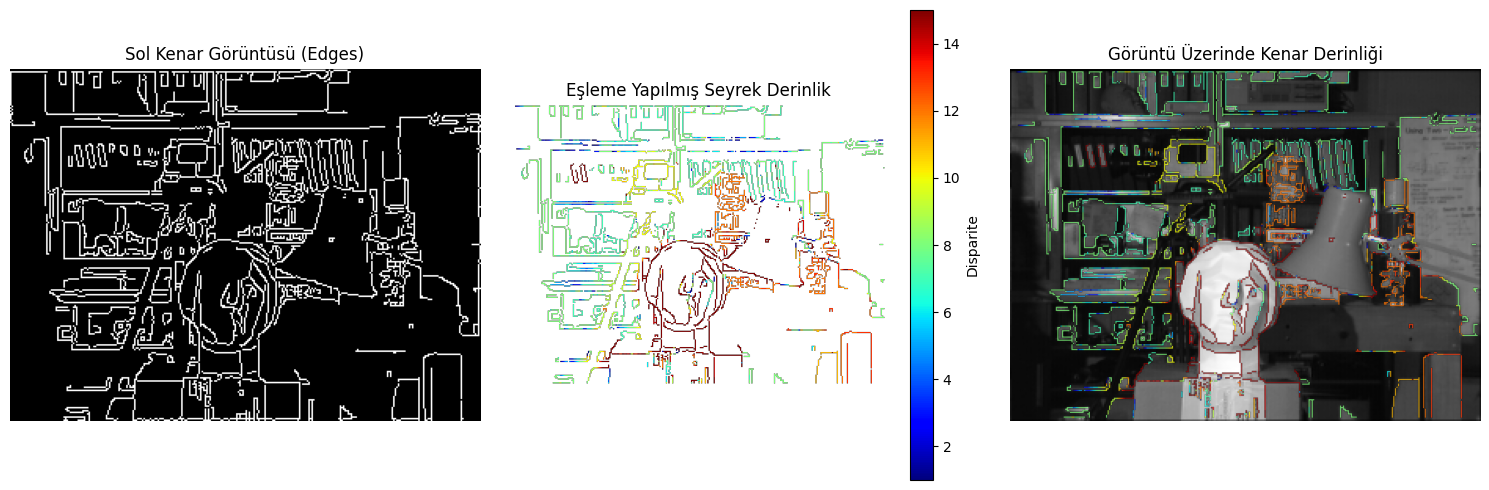

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Görüntüleri Yükleme ve Boyutlandırma
img_l = cv2.imread('/content/görsel.png', cv2.IMREAD_GRAYSCALE)
img_r = cv2.imread('/content/görsel1.png', cv2.IMREAD_GRAYSCALE)

target_w = 300
aspect = img_l.shape[0] / img_l.shape[1]
target_h = int(target_w * aspect)

img_l_res = cv2.resize(img_l, (target_w, target_h))
img_r_res = cv2.resize(img_r, (target_w, target_h))

# 2. Kenar Tespiti (Canny Edge Detection)
t0_edges = time.time()
edges_l = cv2.Canny(img_l_res, 100, 200)
edges_r = cv2.Canny(img_r_res, 100, 200)
t1_edges = time.time()

# 3. Seyrek (Sparse) Stereo Eşleme
# Yalnızca sol görüntüdeki kenar pikselleri (edges_l > 0) üzerinde arama yapacağız.
h, w = img_l_res.shape
sparse_disparity = np.zeros((h, w), dtype=np.float32)
max_disp = 16
block_size = 5
half_b = block_size // 2

t0_sparse = time.time()
# Kenar piksellerinin koordinatlarını bul
edge_indices = np.argwhere(edges_l > 0)

for y, x in edge_indices:
    # Sınır kontrolleri
    if y - half_b < 0 or y + half_b >= h or x - half_b < 0 or x + half_b >= w:
        continue

    best_disp = 0
    min_sad = float('inf')

    # Sol pencere
    win_l = img_l_res[y-half_b:y+half_b+1, x-half_b:x+half_b+1].astype(np.int32)

    # Sağ görüntüde yatay epipolar çizgi boyunca arama yap
    for d in range(max_disp):
        if x - d - half_b >= 0:
            win_r = img_r_res[y-half_b:y+half_b+1, x-d-half_b:x-d+half_b+1].astype(np.int32)
            sad = np.sum(np.abs(win_l - win_r))
            if sad < min_sad:
                min_sad = sad
                best_disp = d

    sparse_disparity[y, x] = best_disp

t1_sparse = time.time()

print(f"Kenar Algılama Süresi: {(t1_edges - t0_edges)*1000:.2f} ms")
print(f"Seyrek Stereo Eşleme Süresi: {(t1_sparse - t0_sparse)*1000:.2f} ms")

# Görselleştirme
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Sol Kenar Görüntüsü (Edges)")
plt.imshow(edges_l, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Eşleme Yapılmış Seyrek Derinlik")
# Sıfır değerlerini (arkaplan/kenar olmayan) maskeleyerek sadece kenarları renkli gösterelim
masked_disp = np.ma.masked_where(sparse_disparity == 0, sparse_disparity)
plt.imshow(masked_disp, cmap='jet')
plt.colorbar(label='Disparite')
plt.axis('off')

plt.subplot(1, 3, 3)
# Orijinal sol resim üzerine bindirilmiş kenar derinlikleri
plt.title("Görüntü Üzerinde Kenar Derinliği")
plt.imshow(img_l_res, cmap='gray')
plt.imshow(masked_disp, cmap='jet', alpha=0.7)
plt.axis('off')

plt.tight_layout()
plt.show()

### Seyrek (Sparse) ve Yoğun (Dense) Stereo Yöntemlerinin Karşılaştırılması

| Kriter | Seyrek (Sparse) Stereo | Yoğun (Dense) Stereo (Örn. SGBM) |
| :--- | :--- | :--- |
| **Hız (Çalışma Süresi)** | **Çok Yüksek:** Hesaplamalar yalnızca kenar ve köşe pikselleri (görüntünün yaklaşık %5-%10'u) üzerinde yapıldığı için işlem yükü son derece düşüktür. | **Düşük / Orta:** Görüntüdeki her bir piksel için ayrı ayrı maliyet hesaplanıp doğrusal/küresel optimizasyon yürütüldüğünden işlem yükü fazladır. |
| **Doğruluk ve Güvenilirlik** | **Yüksek (Kenarlarda):** Dokusuz ve düz bölgelerin getirdiği belirsizlik ve yanlış eşleşme (aperture problem) riski ortadan kalkar. Sadece belirgin doku/kenar detayları eşleştirilir. | **Değişken:** Dokulu alanlarda mükemmel sonuç verirken, düz ve tek renkli duvar veya zemin gibi dokusuz alanlarda yanlış eşleşmeler yapabilir (Yumuşatıcı regularizasyonlar ile çözülmeye çalışılır). |
| **Derinlik Çözünürlüğü** | **Düşük:** Sadece nesne sınırlarında ve hatlarında derinlik bilgisi sunar; nesnelerin iç kısımları boştur (boşluk doldurma interpolasyonları gerekir). | **Yüksek:** Görüntüdeki her piksel için kesintisiz, dolu ve pürüzsüz bir derinlik haritası üretir. |
| **Kullanım Alanları** | Gerçek zamanlı robotik navigasyon, görsel konumlandırma (SLAM), engel tespiti. | 3D Rekonstrüksiyon, otonom sürüş derinlik analizleri, sanal gerçeklik.